# Model time to an event with censoring

A censored follow-up time says that the event had not occurred before follow-up ended. It is not an event at that time and is not a missing outcome to discard. This analysis follows 480 synthetic independent subjects from data preparation to an unseen-subject assessment.

We use one Weibull survival model throughout. Its positive scale changes with a predictor, and its shape is constant. This choice matches the simulated mechanism so the example can focus on censoring, splitting and interpreting predictions rather than model selection. The simulated follow-up uses arbitrary time units.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


from nampy import SurvivalGAM
from nampy.survival import (
    CensoringDistribution, SurvivalTarget, brier_score, concordance_index,
)


In [2]:
def show_figure(figure, name):
    # name is a stable identifier for the corresponding guide figure.
    plt.show()
    plt.close(figure)

In [3]:
rng = np.random.default_rng(73)
X = pd.DataFrame({"x": rng.uniform(-1, 1, 480)})
event_time = np.exp(0.6 - 0.8 * X.x.to_numpy()) * rng.weibull(1.6, len(X))
censoring_time = rng.exponential(4.0, len(X))
target = SurvivalTarget(
    np.minimum(event_time, censoring_time), event_time <= censoring_time,
    subject_id=np.arange(len(X)),
)

## Split subjects before fitting

Each row is a complete subject record, with an ID that stays aligned through the split. All follow-up from a subject belongs to one cohort; with repeated records you must split by subject rather than by row. Here 320 subjects train the model and 160 are held out.

`SurvivalTarget` keeps event indicators separate from predictors. The Weibull likelihood uses a density for an observed event and a survival probability for a right-censored record. We fix smoothing because these are linear parameter predictors; no censoring model is used to fit the event-time model.

In [4]:
# Each row is one subject. Randomize subjects before any model fitting.
order = rng.permutation(len(X))
train, test = order[:320], order[320:]
y_train, y_test = target.take(train), target.take(test)
model = SurvivalGAM(
    likelihood="weibull", formula={"scale": "~x", "shape": "~1"},
    optimize_smoothing=False,
).fit(X.iloc[train], y_train)

## Evaluate on held-out follow-up

Fit the censoring distribution on training outcomes, then supply it explicitly to the IPCW Brier score on test subjects. The horizons 0.5 to 2.0 stay inside observed training and test support. The integrated score averages over those supplied horizons, rather than extrapolating beyond follow-up.

Harrell concordance assesses ordering; here negative restricted mean survival time at horizon 2 defines higher risk. It is a different target from probability accuracy and can depend on censoring. Marginal independent censoring holds in this simulation; this does not demonstrate covariate-dependent censoring adjustment.

In [5]:
prediction = model.predict_distribution(X.iloc[test])
censoring = CensoringDistribution.fit(y_train)
horizons = np.array([0.5, 1.0, 1.5, 2.0])
brier = brier_score(prediction, y_test, horizons, censoring=censoring)
concordance = concordance_index(
    y_test, -prediction.rmst(2.0), higher_risk=True
)

## Inspect records and survival predictions

The follow-up panel marks observed events with circles and right censoring with crosses. Censoring is retained in fitting and evaluation even though its event time is unknown.

At time 2 the fitted survival probabilities for x=-0.8, 0, and 0.8 are approximately 0.65, 0.31, and 0.04. Higher x shortens survival in this simulated model; the curves describe event-free probability, not a predicted event time for a particular person.

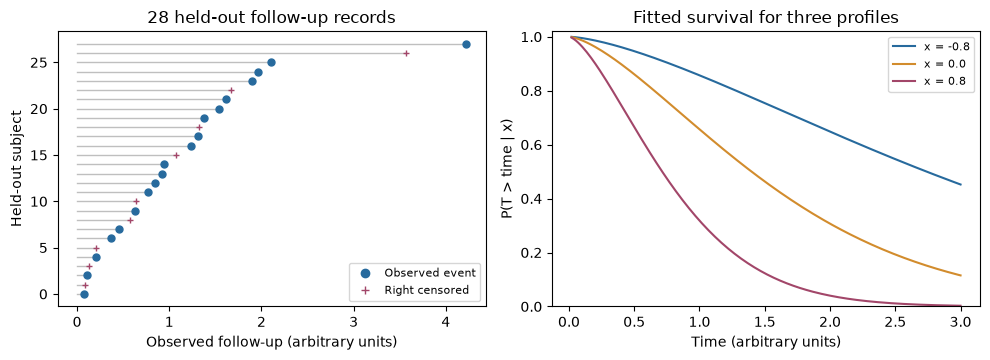

In [6]:
profiles = pd.DataFrame({"x": [-0.8, 0.0, 0.8]})
curves = model.predict_distribution(profiles)
times = np.linspace(0.02, 3, 180)
colors = ["#276A9D", "#D28C2D", "#A24669"]
figure, axes = plt.subplots(1, 2, figsize=(10, 3.7))
rows = test[:28]
rows = rows[np.argsort(target.time[rows])]
for number, row in enumerate(rows):
    axes[0].plot([0, target.time[row]], [number, number], color="0.75", lw=1)
    axes[0].plot(target.time[row], number, "o" if target.event[row] else "+",
                 color="#276A9D" if target.event[row] else "#A24669", ms=5)
axes[0].plot([], [], "o", color="#276A9D", label="Observed event")
axes[0].plot([], [], "+", color="#A24669", label="Right censored")
axes[0].set(xlabel="Observed follow-up (arbitrary units)", ylabel="Held-out subject",
            title="28 held-out follow-up records")
axes[0].legend(fontsize=8)
for row, color in enumerate(colors):
    axes[1].plot(times, curves.survival(times)[row], color=color,
                 label=f"x = {profiles.x.iloc[row]:.1f}")
axes[1].set(xlabel="Time (arbitrary units)", ylabel="P(T > time | x)", ylim=(0, 1.02),
            title="Fitted survival for three profiles")
axes[1].legend(fontsize=8)
figure.tight_layout()
show_figure(figure, "survival_profiles")

## Separate instantaneous hazard from survival

Hazard answers how quickly events occur among those still at risk; survival answers how much event-free probability remains after accumulating those rates. The fitted Weibull shape exceeds one, so hazard rises with time while survival falls. A hazard value is a rate and can exceed one; it is not a probability.

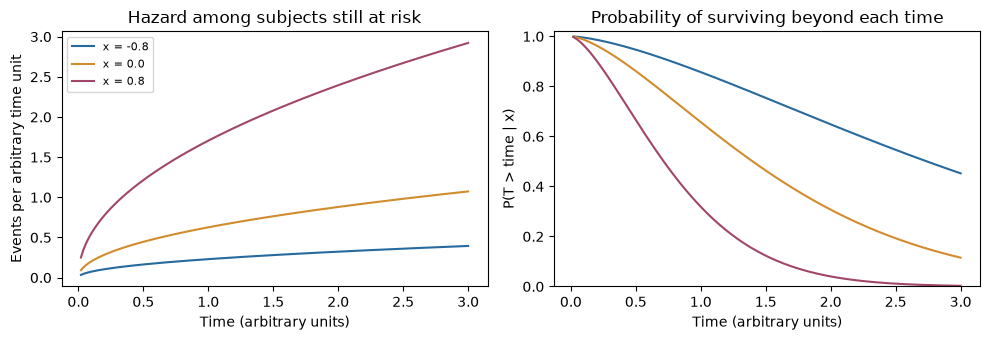

In [7]:
figure, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for row, color in enumerate(colors):
    axes[0].plot(times, curves.hazard(times)[row], color=color,
                 label=f"x = {profiles.x.iloc[row]:.1f}")
    axes[1].plot(times, curves.survival(times)[row], color=color)
axes[0].set(xlabel="Time (arbitrary units)", ylabel="Events per arbitrary time unit",
            title="Hazard among subjects still at risk")
axes[1].set(xlabel="Time (arbitrary units)", ylabel="P(T > time | x)", ylim=(0, 1.02),
            title="Probability of surviving beyond each time")
axes[0].legend(fontsize=8)
figure.tight_layout()
show_figure(figure, "survival_hazard")

## Read the held-out evidence

About 33% of held-out records are censored. This fixed-seed run gives integrated IPCW Brier error about 0.188 and Harrell concordance about 0.669. These are observed scores in one generated dataset, not independent evidence for every supported survival configuration.

In [8]:
print(f"Training subjects: {len(train)}; test subjects: {len(test)}.")
print(f"Right-censored test records: {np.mean(~y_test.event):.1%}.")
print(f"Integrated IPCW Brier error: {brier.integrated():.3f}.")
print(f"Harrell concordance: {concordance.concordance:.3f}.")

Training subjects: 320; test subjects: 160.
Right-censored test records: 33.1%.
Integrated IPCW Brier error: 0.188.
Harrell concordance: 0.669.


## Next analysis decisions

Use a richer predictor only when there is a substantive reason, then repeat the subject-level validation. Check conditional survival calibration and compare a Cox or piecewise route after this primary analysis is complete. See the [survival guide](../user_guide/survival.rst) for model choices and supported entry assumptions.